# Community Detection in Zachary's Karate Club
### DSC212 — Graph Theory Assignment

Param Dalwadi - IMS25057

**Topic:** Finding communities in a network using the modularity matrix and eigenvectors  
**Main reference:** Newman, M. E. J. (2006). *Modularity and community structure in networks*, PNAS 103(23): 8577–8582.  
**Dataset:** Zachary, W. W. (1977). *An Information Flow Model for Conflict and Fission in Small Groups*, JAR 33(4): 452–473.

---

### 1. Importing the required libraries

We use `numpy` for matrices and eigenvalues, `networkx` to work with the graph, `matplotlib` to draw graphs, and `pandas` to organise results in tables. We also set the number of decimal places shown in the output.

In [ ]:
# Scientific Computing Stack
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib as mpl
import pandas as pd

# Global configuration for numerical precision and aesthetic rendering
np.set_printoptions(precision=4, suppress=True, linewidth=120)
plt.rcParams.update({
    "figure.dpi": 130,
    "font.family": "sans-serif",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False
})

print("Scientific computing environment initialized successfully.")


Scientific computing environment initialized successfully.


### 2. Loading the network and building the modularity matrix

**About the dataset:**

Zachary's Karate Club dataset contains 34 people. A line between two people means that they were observed to interact. The dataset also tells us which club each person joined later: Mr. Hi's club or the Officer's club.

We first treat the network as an unweighted graph. This means that a connection is recorded as 1 if two people are connected and 0 otherwise.

Modularity checks whether a group has more connections inside it than we would expect in a random network with the same node degrees. The expected number of connections between nodes \(i\) and \(j\) is

$$P_{ij} = \frac{k_i k_j}{2m}$$

We subtract this expected value from the adjacency matrix to get the **modularity matrix**:

$$B_{ij} = A_{ij} - \frac{k_i k_j}{2m} \implies \mathbf{B} = \mathbf{A} - \frac{\mathbf{k}\mathbf{k}^T}{2m}$$

For a split into two groups, we use \(s_i=+1\) for one group and \(s_i=-1\) for the other. The modularity of this split is

$$Q = \frac{1}{4m}\mathbf{s}^T \mathbf{B} \mathbf{s}.$$

**What the code does:**

1. Loads the Karate Club graph from NetworkX and makes it unweighted.
2. Keeps the actual club labels so that we can compare them with our results later.
3. Builds the adjacency matrix \(A\), the degree vector \(k\), and the modularity matrix \(B\).

In [ ]:
# Ingest raw graph and construct unweighted topological representation
raw_network = nx.karate_club_graph()
G = nx.Graph()
G.add_nodes_from((u, {"club": raw_network.nodes[u]["club"]}) for u in raw_network.nodes)
G.add_edges_from(raw_network.edges())

# Fundamental network dimensions
node_list = sorted(G.nodes())
num_nodes = G.number_of_nodes()
num_edges = G.number_of_edges()
two_m = 2 * num_edges

# Adjacency, degrees, and modularity matrix
adj_matrix = nx.to_numpy_array(G, nodelist=node_list, weight=None)
deg_vector = adj_matrix.sum(axis=1)
modularity_B = adj_matrix - np.outer(deg_vector, deg_vector) / two_m

# Verify structural invariants
ground_truth_counts = pd.Series([G.nodes[v]["club"] for v in node_list]).value_counts().to_dict()

print(f"Network Nodes (n)         : {num_nodes}")
print(f"Network Edges (m)         : {num_edges}")
print(f"Degree Sum (sum k_i)      : {int(deg_vector.sum())} (Invariance Check: 2m = {two_m})")
print(f"Average Node Degree <k>   : {deg_vector.mean():.2f}")
print(f"Ground-Truth Faction Distribution: {ground_truth_counts}")


Network Nodes (n)         : 34
Network Edges (m)         : 78
Degree Sum (sum k_i)      : 156 (Invariance Check: 2m = 156)
Average Node Degree <k>   : 4.59
Ground-Truth Faction Distribution: {'Mr. Hi': 17, 'Officer': 17}


### 3. Checking some properties of the modularity matrix

Before using the matrix, we check a few properties that follow from its definition.

- **Symmetry:** The adjacency matrix is symmetric because the graph is undirected. The matrix \(kk^T\) is also symmetric. Therefore, \(B\) is symmetric. This is useful because a real symmetric matrix has real eigenvalues and can be diagonalised using orthonormal eigenvectors.
- **Zero row sums:** Every row of \(B\) adds up to zero. In matrix form, \(B\mathbf{1}=\mathbf{0}\). So the all-ones vector is an eigenvector with eigenvalue zero.
- **Modularity of one group:** If all nodes are placed in the same group, the modularity is zero.
- **Largest eigenvalue:** The Rayleigh–Ritz theorem says that the largest value of \(x^TBx\), for a unit vector \(x\), is the largest eigenvalue of \(B\). This value is reached when \(x\) is the corresponding eigenvector.

**What we check in the code:**

We check whether \(B\) is symmetric, whether its row sums are close to zero, and whether putting all nodes in one group gives modularity zero. We then calculate the eigenvalues and eigenvectors. Finally, we compare the largest-eigenvalue result with 25,000 randomly generated unit vectors.

In [ ]:
# 1. Symmetry verification (Proposition 1)
is_symmetric = np.allclose(modularity_B, modularity_B.T, atol=1e-14)
print(f"Proposition 1 | B is symmetric                 : {is_symmetric}")

# 2. Row-sum nullification (Proposition 2)
ones_vector = np.ones(num_nodes)
row_sum_residual = np.max(np.abs(modularity_B @ ones_vector))
print(f"Proposition 2 | ||B * 1||_inf                   : {row_sum_residual:.2e} (Zero Vector)")

# 3. Trivial partition modularity (Corollary 1)
Q_trivial = (ones_vector @ modularity_B @ ones_vector) / (2 * two_m)
print(f"Corollary 1   | Modularity of single community : {Q_trivial:.6e}")

# 4. Eigenspectrum decomposition
eigenvals, eigenvecs = np.linalg.eigh(modularity_B)
leading_eval = eigenvals[-1]
leading_evec = eigenvecs[:, -1]

print(f"\nTop 5 Eigenvalues of Matrix B                  : {eigenvals[::-1][:5]}")
print(f"Has Eigenvalue Identically Zero (lambda = 0)   : {np.isclose(eigenvals, 0.0, atol=1e-12).any()}")

# 5. Rayleigh-Ritz empirical bound test (Theorem 2)
rng_generator = np.random.default_rng(seed=2024)
random_quadratic_forms = []
for _ in range(25000):
    rnd_vec = rng_generator.normal(size=num_nodes)
    rnd_vec /= np.linalg.norm(rnd_vec)
    random_quadratic_forms.append(rnd_vec @ modularity_B @ rnd_vec)

max_random_val = max(random_quadratic_forms)
optimal_val = leading_evec @ modularity_B @ leading_evec

print(f"\nTheorem 2 (Rayleigh-Ritz Characterization):")
print(f"  • Max quadratic form over 25,000 random unit vectors : {max_random_val:.4f}")
print(f"  • Theoretical upper bound (leading eigenvalue lam1)  : {leading_eval:.4f}")
print(f"  • Optimal evaluation achieved by leading vector u1    : {optimal_val:.4f}")
assert max_random_val <= leading_eval + 1e-10, "Empirical violation of Rayleigh-Ritz theorem!"


Proposition 1 | B is symmetric                 : True
Proposition 2 | ||B * 1||_inf                   : 8.88e-16 (Zero Vector)
Corollary 1   | Modularity of single community : 1.120898e-17

Top 5 Eigenvalues of Matrix B                  : [4.9771 3.0428 2.3202 1.4888 1.4594]
Has Eigenvalue Identically Zero (lambda = 0)   : True

Theorem 2 (Rayleigh-Ritz Characterization):
  • Max quadratic form over 25,000 random unit vectors : 2.2206
  • Theoretical upper bound (leading eigenvalue lam1)  : 4.9771
  • Optimal evaluation achieved by leading vector u1    : 4.9771


### 4. Splitting a community into two groups

We first use the modularity matrix to divide the full network into two groups. To find more than two groups, we repeat this process on the groups that we have already found.

#### Why do we need a corrected matrix?

When we focus on only one community \(C\), we might think that we can simply take the part of \(B\) containing the rows and columns of nodes in \(C\). However, this does not give the correct change in modularity for splitting that community. We must also account for connections from its nodes to nodes outside the community.

Newman's corrected matrix is

$$B^{(C)}_{ij} = B_{ij} - \delta_{ij} \sum_{k \in C} B_{ik}, \quad i,j \in C.$$

The correction changes the diagonal entries so that every row of the new matrix adds up to zero:

$$\sum_{j \in C} B^{(C)}_{ij}=0.$$

#### When should we stop splitting?

- If the largest eigenvalue of the corrected matrix is zero or negative, the split cannot give a positive modularity gain. We can stop splitting that community.
- If the largest eigenvalue is positive, a useful split may exist, but it is not guaranteed. We still need to check the actual modularity gain after assigning nodes using the signs of the eigenvector.
- This final check matters because converting the eigenvector into +1 and -1 labels may not give a better split.

Using the uncorrected part of the matrix can give misleading results because connections to nodes outside the selected community are ignored. The correction avoids this problem.

**Main functions used in the code:**

- `calculate_global_modularity(membership)`: calculates the modularity of the current grouping.
- `extract_dominant_eigenpair(matrix)`: finds the largest eigenvalue and its eigenvector.
- `construct_subgroup_matrix(nodes, corrected=True)`: builds the matrix for a selected community, including the correction when requested.
- `bipartition_cluster(nodes, corrected, guard)`: tries to divide a community and checks whether the split improves modularity.
- `execute_recursive_partitioning()`: repeats the splitting process and saves the results at each step.

In [ ]:
EPSILON_TOLERANCE = 1e-10

def calculate_global_modularity(membership_labels):
    """Calculates total global modularity Q = (1 / 2m) * sum_{i,j} B_ij * delta(c_i, c_j)."""
    labels_arr = np.asarray(membership_labels)
    co_membership_mask = (labels_arr[:, None] == labels_arr[None, :])
    return np.sum(modularity_B * co_membership_mask) / two_m

def extract_dominant_eigenpair(symmetric_matrix):
    """Extracts the largest eigenvalue and its deterministically oriented eigenvector."""
    evals, evecs = np.linalg.eigh(symmetric_matrix)
    top_vec = evecs[:, -1].copy()
    # Normalize sign orientation: set largest-magnitude element to positive
    top_vec *= np.sign(top_vec[np.argmax(np.abs(top_vec))])
    return evals[-1], top_vec

def construct_subgroup_matrix(subgroup_nodes, corrected=True):
    """Extracts restricted modularity matrix B^(C) with optional row-sum diagonal adjustment."""
    sub_indices = list(subgroup_nodes)
    matrix_block = modularity_B[np.ix_(sub_indices, sub_indices)].copy()
    if corrected:
        matrix_block -= np.diag(matrix_block.sum(axis=1))
    return matrix_block

def bipartition_cluster(cluster_nodes, corrected=True, guard=True):
    """Attempts spectral bisection of candidate cluster. Returns (lam1, C_plus, C_minus, dQ)."""
    cluster = list(cluster_nodes)
    if len(cluster) <= 1:
        return 0.0, None, None, None

    M_sub = construct_subgroup_matrix(cluster, corrected=corrected)
    lam_1, u_1 = extract_dominant_eigenpair(M_sub)

    # Stopping Condition 1: Non-positive leading eigenvalue
    if lam_1 <= EPSILON_TOLERANCE:
        return lam_1, None, None, None

    # Discrete projection via sign thresholding
    s_discrete = np.where(u_1 > 0, 1.0, -1.0)
    subset_plus = [cluster[i] for i in range(len(cluster)) if s_discrete[i] > 0]
    subset_minus = [cluster[i] for i in range(len(cluster)) if s_discrete[i] < 0]

    # Stopping Condition 2: Degenerate single-sided split
    if not subset_plus or not subset_minus:
        return lam_1, None, None, None

    # Calculate exact modularity delta: Delta Q = s^T B^(C) s / (4m)
    delta_Q = (s_discrete @ M_sub @ s_discrete) / (2 * two_m)

    # Stopping Condition 3: Discrete safeguard (thresholding must yield positive modularity gain)
    if guard and delta_Q <= EPSILON_TOLERANCE:
        return lam_1, None, None, delta_Q

    return lam_1, subset_plus, subset_minus, delta_Q

def execute_recursive_partitioning(corrected=True, guard=True):
    """Orchestrates queue-based recursive bisection across all active community branches."""
    node_assignments = np.zeros(num_nodes, dtype=int)
    trajectory = [dict(
        step=0,
        assignments=node_assignments.copy(),
        lambda1=None,
        delta_Q=None,
        split_desc="Root Graph",
        modularity=calculate_global_modularity(node_assignments)
    )]

    split_queue = [(0, list(range(num_nodes)))]
    stopped_branches = []
    next_comm_id = 1
    step_counter = 0

    while split_queue:
        active_id, active_nodes = split_queue.pop(0)
        lam1, c_pos, c_neg, dQ = bipartition_cluster(active_nodes, corrected=corrected, guard=guard)

        if c_pos is None:
            stopped_branches.append((active_id, active_nodes, lam1, dQ))
            continue

        step_counter += 1
        node_assignments = node_assignments.copy()
        node_assignments[c_neg] = next_comm_id

        trajectory.append(dict(
            step=step_counter,
            assignments=node_assignments.copy(),
            lambda1=lam1,
            delta_Q=dQ,
            split_desc=f"Cluster {active_id} -> ({active_id}, {next_comm_id})",
            modularity=calculate_global_modularity(node_assignments)
        ))

        split_queue.append((active_id, c_pos))
        split_queue.append((next_comm_id, c_neg))
        next_comm_id += 1

    return trajectory, stopped_branches

# Execute recursive modularity partitioning using Newman-corrected formulation
partition_trajectory, final_community_diagnostics = execute_recursive_partitioning(corrected=True, guard=True)

# Generate audit report
audit_records = []
for h in partition_trajectory:
    split_label = h['split_desc']
    eval_str = f"{h['lambda1']:.4f}" if h['lambda1'] is not None else "-"
    gain_str = f"{h['delta_Q']:.4f}" if h['delta_Q'] is not None else "-"
    audit_records.append({
        "Iteration": h['step'],
        "Bisection Action": split_label,
        "Leading λ1": eval_str,
        "Gain ΔQ": gain_str,
        "Total Communities": len(set(h['assignments'])),
        "Global Modularity Q": round(h['modularity'], 4)
    })

audit_summary_df = pd.DataFrame(audit_records)
print("=== RECURSIVE MODULARITY PARTITIONING AUDIT LOG ===")
print(audit_summary_df.to_string(index=False))

# Mathematical verification of additive modularity gain
for i in range(1, len(partition_trajectory)):
    q_prev = partition_trajectory[i-1]['modularity']
    q_curr = partition_trajectory[i]['modularity']
    dq_claimed = partition_trajectory[i]['delta_Q']
    assert abs(q_curr - q_prev - dq_claimed) < 1e-9, f"Modularity delta mismatch at step {i}!"

print("\nAdditive modularity consistency verified: Q(t) - Q(t-1) == Delta Q holds across all iterations.")
print("\nFinal Stable Communities & Invariance Criteria:")
for cid, nodes_in_c, lam_val, dQ_val in sorted(final_community_diagnostics, key=lambda x: x[0]):
    stop_rationale = "Spectral stopping rule: lambda1 <= 0" if lam_val <= EPSILON_TOLERANCE else f"Discrete safeguard: Delta Q ({dQ_val:.4f}) <= 0"
    print(f"  • Community {cid} (Size: {len(nodes_in_c):>2}): λ1 = {lam_val:7.4f} | {stop_rationale}")
    print(f"    Members: {sorted(nodes_in_c)}")


=== RECURSIVE MODULARITY PARTITIONING AUDIT LOG ===
 Iteration    Bisection Action Leading λ1 Gain ΔQ  Total Communities  Global Modularity Q
         0          Root Graph          -       -                  1              -0.0000
         1 Cluster 0 -> (0, 1)     4.9771  0.3715                  2               0.3715
         2 Cluster 0 -> (0, 2)     1.1785  0.0012                  3               0.3727
         3 Cluster 1 -> (1, 3)     0.8594  0.0207                  4               0.3934

Additive modularity consistency verified: Q(t) - Q(t-1) == Delta Q holds across all iterations.

Final Stable Communities & Invariance Criteria:
  • Community 0 (Size:  9): λ1 =  0.0602 | Discrete safeguard: Delta Q (-0.0158) <= 0
    Members: [1, 2, 3, 7, 12, 13, 17, 19, 21]
  • Community 1 (Size:  6): λ1 =  0.0000 | Spectral stopping rule: lambda1 <= 0
    Members: [23, 24, 25, 27, 28, 31]
  • Community 2 (Size:  7): λ1 = -0.0000 | Spectral stopping rule: lambda1 <= 0
    Members: [0, 4, 5,

### 5. How the communities form after each split

The network is drawn after every round of splitting. We keep the positions of the nodes fixed so that we can easily see which nodes change groups. Different colours show different communities, and the node numbers help us identify each person.

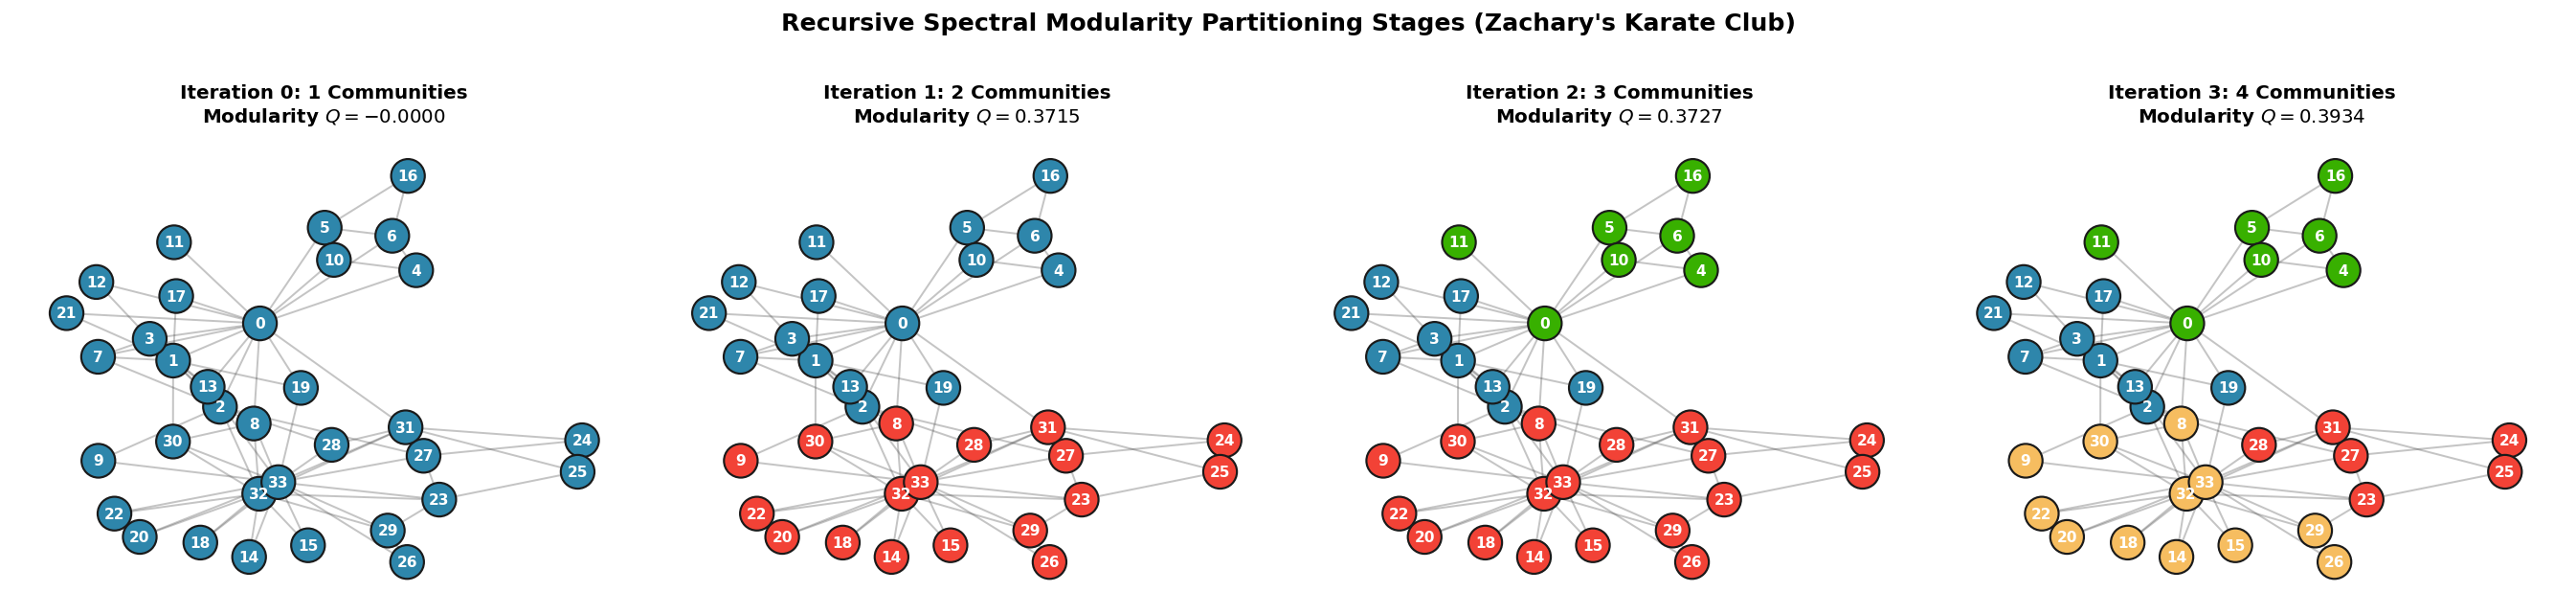

In [ ]:
# Deterministic visual coordinates and custom palette
fixed_layout_coords = nx.spring_layout(G, seed=42, k=0.55, iterations=250)
curated_palette = ['#2E86AB', '#F24236', '#38B000', '#F6BD60', '#845EC2', '#D65DB1', '#00C9A7']

num_stages = len(partition_trajectory)
fig, axes = plt.subplots(1, num_stages, figsize=(5.2 * num_stages, 4.8))

for idx, stage in enumerate(partition_trajectory):
    ax = axes[idx]
    current_labels = stage["assignments"]
    vertex_colors = [curated_palette[current_labels[v] % len(curated_palette)] for v in node_list]

    # Render edges and vertices
    nx.draw_networkx_edges(G, fixed_layout_coords, ax=ax, alpha=0.32, width=1.1, edge_color='#4A4A4A')
    nx.draw_networkx_nodes(G, fixed_layout_coords, ax=ax, node_color=vertex_colors,
                           node_size=380, edgecolors='#1A1A1A', linewidths=1.2)
    nx.draw_networkx_labels(G, fixed_layout_coords, ax=ax, font_size=8.5, font_weight='bold', font_color='white')

    num_c = len(set(current_labels))
    ax.set_title(f"Iteration {stage['step']}: {num_c} Communities\nModularity $Q = {stage['modularity']:.4f}$",
                 fontsize=11, fontweight='bold', pad=8)
    ax.axis('off')

plt.suptitle("Recursive Spectral Modularity Partitioning Stages (Zachary's Karate Club)",
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


### 6. Measuring how important each node is inside its community

We calculate four measures for every node, using only the nodes in its current community.

1. **Degree centrality:** Measures how many direct connections a node has compared with the maximum possible number of connections in that community.
   $$C_D(i)=\frac{k_i^{(C)}}{|C|-1}$$
2. **Betweenness centrality:** Measures how often a node lies on the shortest paths between other pairs of nodes in the same community.
   $$C_B(i)=\sum_{s \ne i \ne t \in C}\frac{\sigma_{st}(i)}{\sigma_{st}}$$
3. **Closeness centrality:** Measures how close a node is to the other nodes, based on shortest-path distances.
   $$C_C(i)=\frac{|C|-1}{\sum_{j \in C, j \ne i}d(i,j)}$$
4. **Clustering coefficient:** Measures how well a node's neighbours are connected to each other. It is high when many triangles are formed around the node.
   $$C(i)=\frac{2T(i)}{k_i(k_i-1)}$$

**What the code does:**

The function `evaluate_community_subgraph_metrics()` looks at each community, creates the graph containing only its members, and calculates the four measures above. It also handles communities with only one node, for which the values are set to zero.

In [ ]:
def evaluate_community_subgraph_metrics(membership_assignments):
    """Computes degree, betweenness, closeness, and clustering across community-induced subgraphs."""
    extracted_metrics = {"degree": {}, "betweenness": {}, "closeness": {}, "clustering": {}}
    unique_communities = sorted(set(membership_assignments))

    for comm_id in unique_communities:
        cluster_members = [v for v in node_list if membership_assignments[v] == comm_id]
        subgraph = G.subgraph(cluster_members)

        # Singletons or disconnected vertices have null centralities
        if len(cluster_members) == 1:
            for m_key in extracted_metrics:
                extracted_metrics[m_key][cluster_members[0]] = 0.0
            continue

        deg_res = nx.degree_centrality(subgraph)
        bet_res = nx.betweenness_centrality(subgraph)
        cls_res = nx.closeness_centrality(subgraph)
        clu_res = nx.clustering(subgraph)

        extracted_metrics["degree"].update(deg_res)
        extracted_metrics["betweenness"].update(bet_res)
        extracted_metrics["closeness"].update(cls_res)
        extracted_metrics["clustering"].update(clu_res)

    return extracted_metrics

# Store metric histories: historical_metrics[metric_name][iteration][node_id]
historical_metrics = {"degree": {}, "betweenness": {}, "closeness": {}, "clustering": {}}
for stage in partition_trajectory:
    step_num = stage["step"]
    computed = evaluate_community_subgraph_metrics(stage["assignments"])
    for m_key in historical_metrics:
        historical_metrics[m_key][step_num] = computed[m_key]

# Baseline assertion: Iteration 0 must identically match global graph calculations
assert all(abs(historical_metrics["degree"][0][v] - nx.degree_centrality(G)[v]) < 1e-12 for v in node_list)
assert all(abs(historical_metrics["clustering"][0][v] - nx.clustering(G)[v]) < 1e-12 for v in node_list)

# Format structured pandas tables across iterations
iteration_steps = [s["step"] for s in partition_trajectory]
metric_tables = {
    m_key: pd.DataFrame({it: historical_metrics[m_key][it] for it in iteration_steps}).round(3)
    for m_key in historical_metrics
}

metric_formal_titles = {
    "degree": "Degree Centrality (Local Normalized)",
    "betweenness": "Betweenness Centrality (Intra-Community Shortest Paths)",
    "closeness": "Closeness Centrality (Intra-Community Reachability)",
    "clustering": "Clustering Coefficient (Triadic Closure)"
}

print("Node metrics successfully computed across all iterations.")
for m_key in ("degree", "closeness", "clustering", "betweenness"):
    print(f"\n--- {metric_formal_titles[m_key]} (Sample: Nodes 0-10) ---")
    print(metric_tables[m_key].head(10).to_string())


Node metrics successfully computed across all iterations.

--- Degree Centrality (Local Normalized) (Sample: Nodes 0-10) ---
       0      1      2      3
0  0.485  0.933  0.833  0.833
1  0.273  0.533  0.875  0.875
2  0.303  0.333  0.500  0.500
3  0.182  0.400  0.625  0.625
4  0.091  0.200  0.500  0.500
5  0.121  0.267  0.667  0.667
6  0.121  0.267  0.667  0.667
7  0.121  0.267  0.375  0.375
8  0.152  0.176  0.176  0.273
9  0.061  0.059  0.059  0.091

--- Closeness Centrality (Intra-Community Reachability) (Sample: Nodes 0-10) ---
       0      1      2      3
0  0.569  0.938  0.857  0.857
1  0.485  0.652  0.889  0.889
2  0.559  0.577  0.667  0.667
3  0.465  0.600  0.727  0.727
4  0.379  0.556  0.667  0.667
5  0.384  0.577  0.750  0.750
6  0.384  0.577  0.750  0.750
7  0.440  0.556  0.615  0.615
8  0.516  0.515  0.515  0.579
9  0.434  0.486  0.486  0.524

--- Clustering Coefficient (Triadic Closure) (Sample: Nodes 0-10) ---
       0      1      2      3
0  0.150  0.187  0.400  0.400
1 

### 7. How the centrality values change after each split

For each of the four measures, we make two plots:

- **Line plot:** Shows how the value changes over the splitting steps. We highlight important nodes, including Node 0 (Mr. Hi) and Node 33 (the Officer).
- **Heatmap:** Shows the values for all 34 nodes at each step. This makes it easier to see how the values change across the whole network.

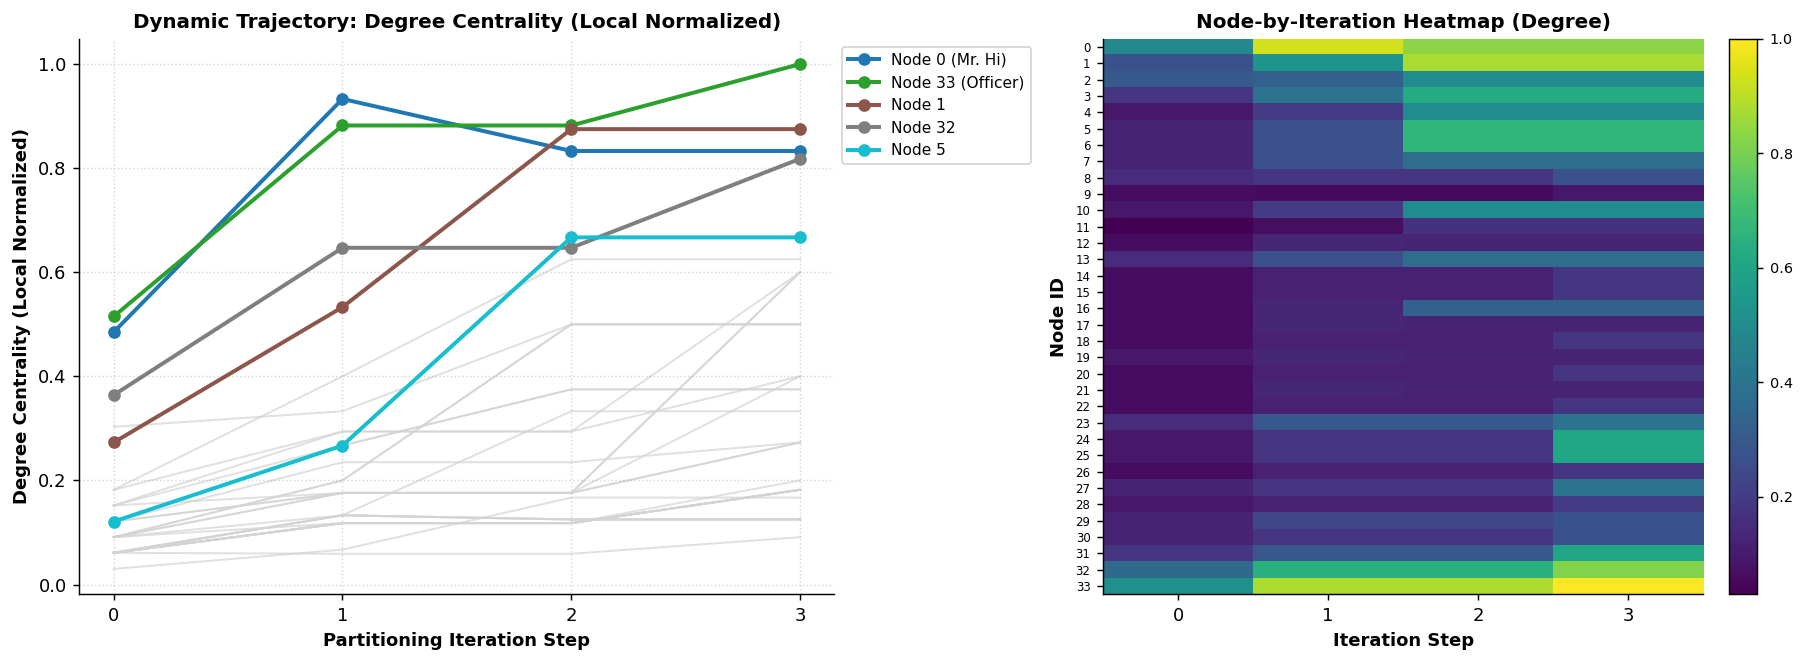

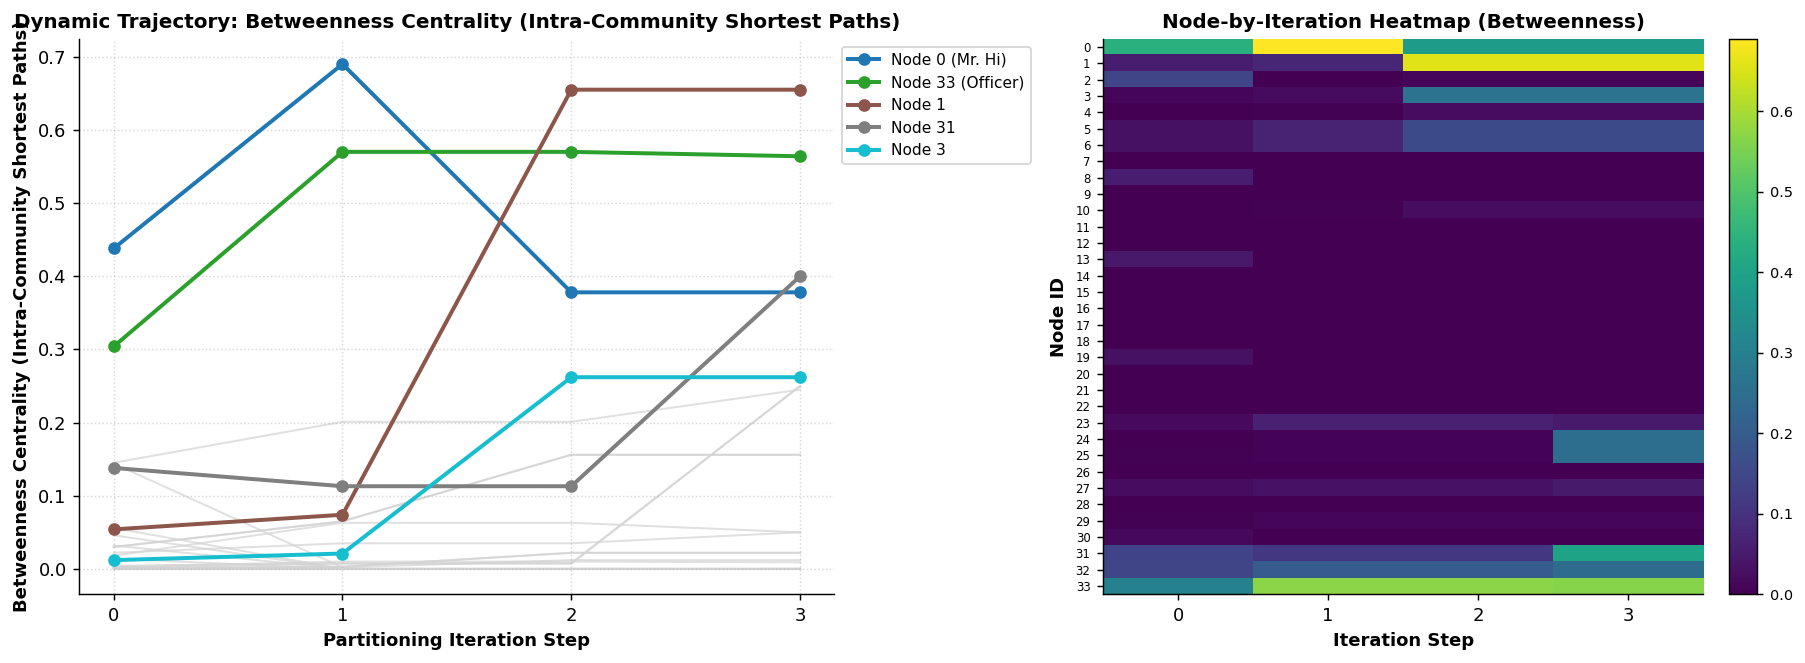

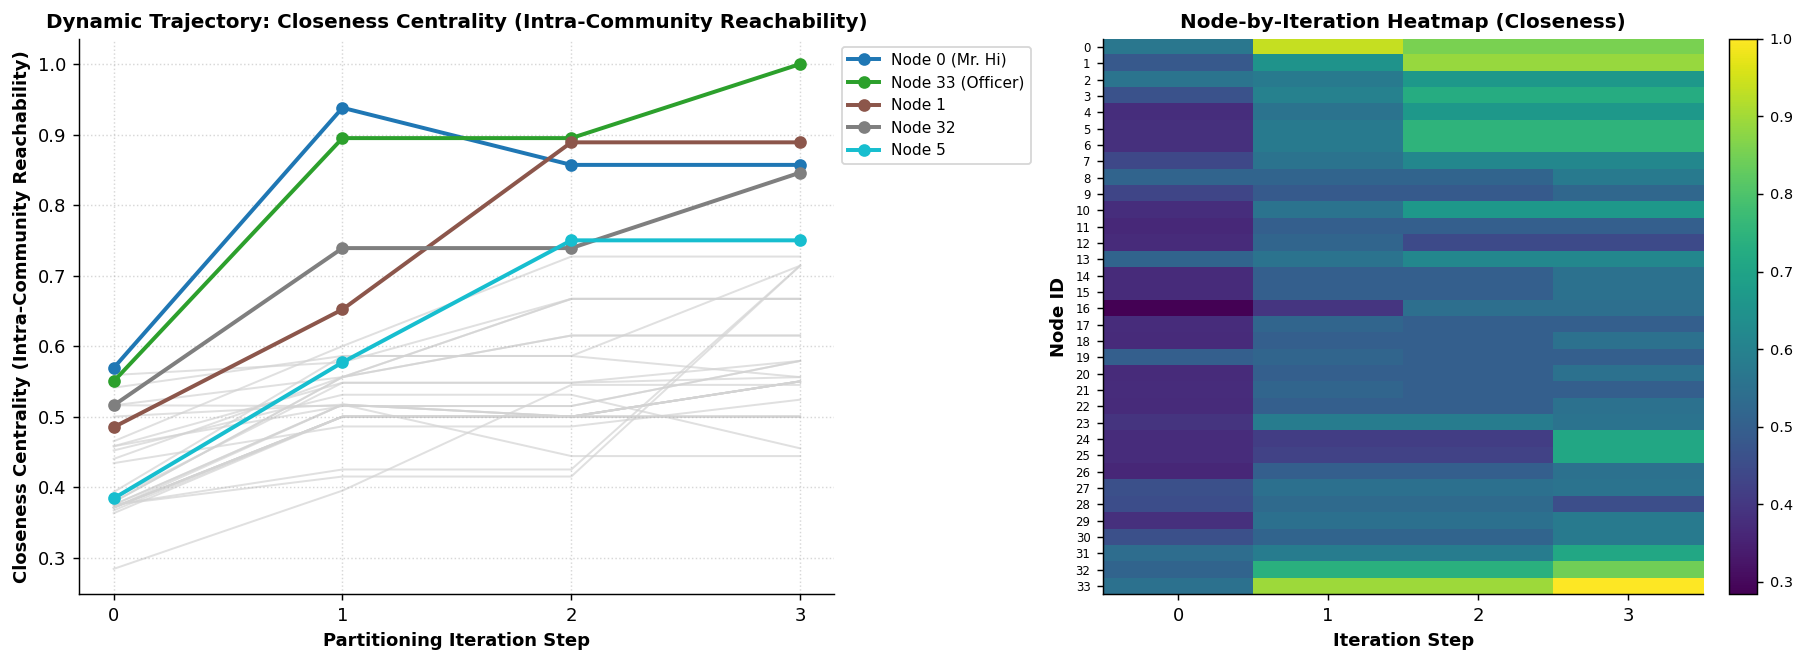

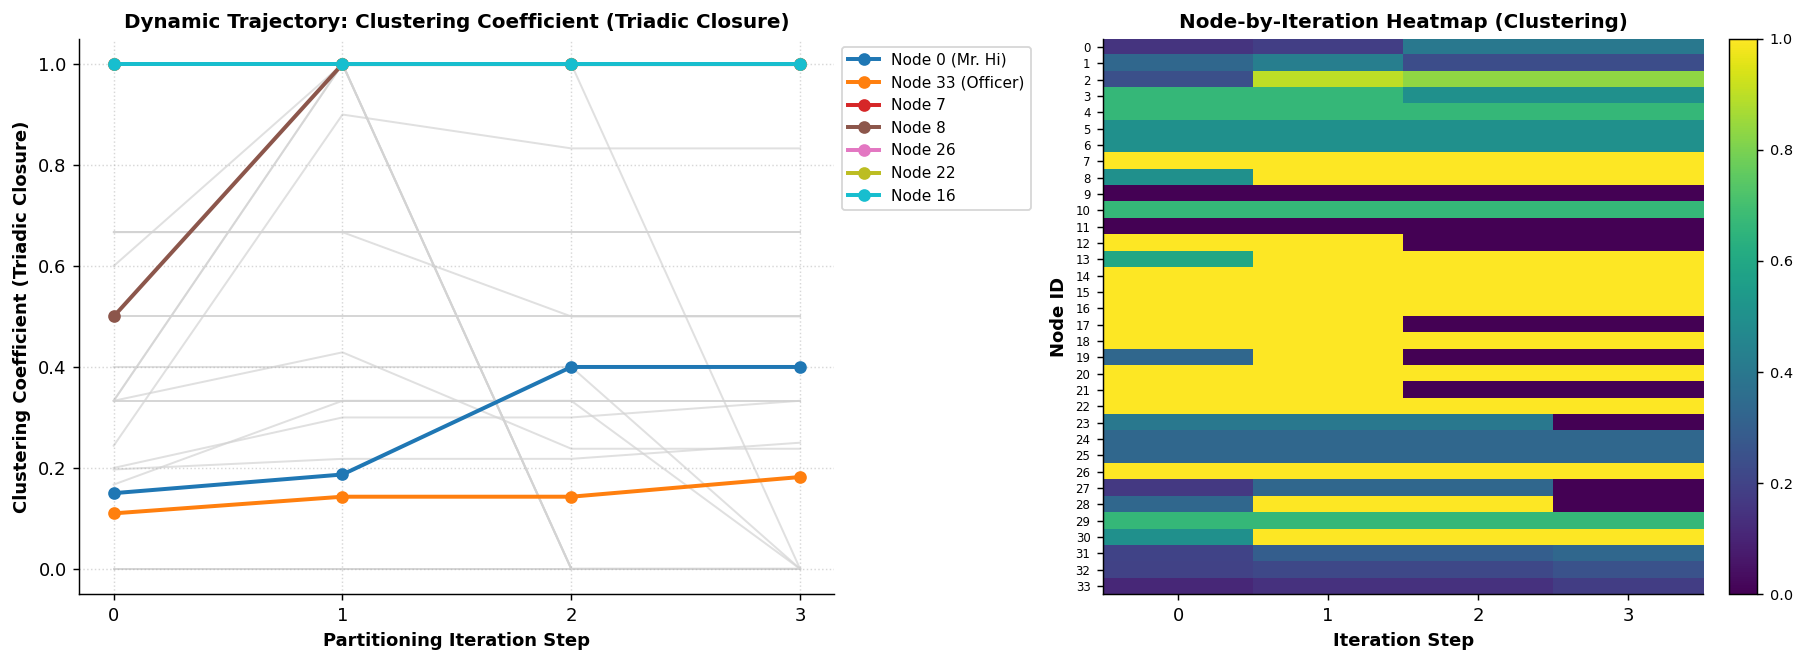

In [ ]:
final_iteration_idx = iteration_steps[-1]

for m_key, title_str in metric_formal_titles.items():
    df_data = metric_tables[m_key]

    # Identify institutional anchors and top performers at final stage
    top_performers = list(df_data[final_iteration_idx].sort_values(ascending=False).index[:5])
    focal_nodes = list(dict.fromkeys([0, 33] + top_performers))

    fig, (ax_line, ax_heat) = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.15, 1.0]})

    # Line plot: background trajectories
    for v in node_list:
        if v not in focal_nodes:
            ax_line.plot(iteration_steps, df_data.loc[v], color='#D3D3D3', lw=1.1, alpha=0.7, zorder=1)

    # Highlighted focal nodes
    focal_palette = plt.cm.tab10(np.linspace(0, 1, len(focal_nodes)))
    for idx_f, f_node in enumerate(focal_nodes):
        label_text = f"Node {f_node}"
        if f_node == 0: label_text += " (Mr. Hi)"
        elif f_node == 33: label_text += " (Officer)"

        ax_line.plot(iteration_steps, df_data.loc[f_node], marker='o', markersize=6, lw=2.2,
                     color=focal_palette[idx_f], label=label_text, zorder=3)

    ax_line.set_xticks(iteration_steps)
    ax_line.set_xlabel("Partitioning Iteration Step", fontsize=10, fontweight='bold')
    ax_line.set_ylabel(title_str, fontsize=10, fontweight='bold')
    ax_line.set_title(f"Dynamic Trajectory: {title_str}", fontsize=11, fontweight='bold')
    ax_line.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=8.5, frameon=True)
    ax_line.grid(True, linestyle=":", alpha=0.5)

    # Heatmap matrix
    heatmap_im = ax_heat.imshow(df_data.values, aspect="auto", cmap="viridis", interpolation='nearest')
    ax_heat.set_xticks(range(len(iteration_steps)))
    ax_heat.set_xticklabels(iteration_steps)
    ax_heat.set_yticks(range(num_nodes))
    ax_heat.set_yticklabels(df_data.index, fontsize=6.5)
    ax_heat.set_xlabel("Iteration Step", fontsize=10, fontweight='bold')
    ax_heat.set_ylabel("Node ID", fontsize=10, fontweight='bold')
    ax_heat.set_title(f"Node-by-Iteration Heatmap ({m_key.capitalize()})", fontsize=11, fontweight='bold')

    cbar = fig.colorbar(heatmap_im, ax=ax_heat, fraction=0.046, pad=0.04)
    cbar.ax.tick_params(labelsize=8)

    plt.tight_layout()
    plt.show()


### 8. Which nodes remain important throughout the process?

A node may be important in one step but less important in another. To get a clearer picture, we rank the nodes for each centrality measure at every step. Rank 1 means the highest value.

We then calculate the average ranks across the different measures and steps. This helps us find nodes that remain important throughout the splitting process.

In [ ]:
# Ordinal rank computation (Rank 1 = Highest score)
rank_matrices = {m_key: metric_tables[m_key].rank(ascending=False, method="min") for m_key in historical_metrics}

# Aggregate mean ranks across iterations per metric
mean_rank_summary = pd.DataFrame({
    f"{m_key.capitalize()} Mean Rank": rank_matrices[m_key].mean(axis=1)
    for m_key in historical_metrics
})

# Composite centrality index (lower score indicates superior persistence)
mean_rank_summary["Composite Index"] = mean_rank_summary.mean(axis=1)
mean_rank_summary = mean_rank_summary.sort_values("Composite Index").round(2)

print("=== TOP 8 MOST PERSISTENTLY CENTRAL NETWORK ACTORS ===")
print(mean_rank_summary.head(8).to_string())

print("\n=== TOP 3 NODES PER METRIC ACROSS ITERATIONS ===")
for m_key in historical_metrics:
    print(f"\nMetric: {metric_formal_titles[m_key]}")
    for it_step in iteration_steps:
        top_slice = metric_tables[m_key][it_step].sort_values(ascending=False).head(3)
        formatted_leaders = ", ".join([f"Node {v} ({val:.3f})" for v, val in top_slice.items()])
        print(f"  Step {it_step}: {formatted_leaders}")


=== TOP 8 MOST PERSISTENTLY CENTRAL NETWORK ACTORS ===
    Degree Mean Rank  Betweenness Mean Rank  Closeness Mean Rank  Clustering Mean Rank  Composite Index
0               2.25                   2.25                 2.00                 25.25             7.94
33              1.25                   2.00                 1.75                 29.25             8.56
1               3.25                   3.50                 4.25                 24.00             8.75
3               6.25                   8.50                 7.25                 15.75             9.44
32              4.00                   4.75                 4.50                 27.25            10.12
13             11.00                  14.75                10.25                  4.75            10.19
6               7.25                   7.75                 8.50                 18.00            10.38
5               7.25                   7.75                 8.50                 18.00            10.38

=== TOP 

### 9. Comparing the results and checking the matrix correction

We carry out two checks:

1. **Compare with the actual club split:** We compare the first division found by our method with the historical division of the Karate Club.
2. **Check the matrix correction:** We run the recursive splitting method again using the uncorrected submatrix. Comparing the results shows why Newman's diagonal correction and the modularity-gain check are needed.

In [ ]:
# 1. Ground truth recovery evaluation
first_split_labels = partition_trajectory[1]["assignments"]
empirical_truth = np.array([0 if G.nodes[v]["club"] == "Mr. Hi" else 1 for v in node_list])

# Align arbitrary eigenvector sign polarity
mismatch_scenario_1 = np.where(first_split_labels != empirical_truth)[0]
mismatch_scenario_2 = np.where(first_split_labels == empirical_truth)[0]
actual_mismatches = [int(v) for v in (mismatch_scenario_1 if len(mismatch_scenario_1) <= len(mismatch_scenario_2) else mismatch_scenario_2)]

accuracy_score = (num_nodes - len(actual_mismatches)) / num_nodes
print(f"First Spectral Bipartition Accuracy : {accuracy_score:.2%} ({num_nodes - len(actual_mismatches)}/{num_nodes} nodes)")
print(f"Misclassified Node(s)              : Node {actual_mismatches}")
print(f"Predicted Split Proportions        : {np.bincount(first_split_labels)} vs Historical: {np.bincount(empirical_truth)}")

# 2. Execution of naive un-corrected submatrix recursion
traj_naive, stopped_naive = execute_recursive_partitioning(corrected=False, guard=False)

print("\n=== MODULARITY TRAJECTORY COMPARISON ===")
print(f"{'Step':>4} | {'Naive Raw Block Q':>18} | {'Newman-Corrected Q':>19}")
max_steps = max(len(partition_trajectory), len(traj_naive))
for s_idx in range(max_steps):
    q_naive = f"{traj_naive[s_idx]['modularity']:.4f}" if s_idx < len(traj_naive) else "-"
    q_corr  = f"{partition_trajectory[s_idx]['modularity']:.4f}" if s_idx < len(partition_trajectory) else "-"
    print(f"{s_idx:>4} | {q_naive:>18} | {q_corr:>19}")

print(f"\nFinal Clusters (Newman Corrected) : {sorted(sorted(c) for _, c, _, _ in final_community_diagnostics)}")
print(f"Final Clusters (Naive Raw Block)  : {sorted(sorted(c) for _, c, _, _ in stopped_naive)}")

# Demonstrate false positive eigenvalues in raw block formulation
print("\nDemonstration of Naive Submatrix Pathology (lambda1 > 0 on Indivisible Groups):")
for cid, nodes_sub, lam_sub, dq_sub in sorted(stopped_naive, key=lambda x: x[0]):
    if lam_sub > EPSILON_TOLERANCE:
        print(f"  • Cluster {cid} (Size: {len(nodes_sub):>2}): λ1 = {lam_sub:.4f} > 0, but eigenvector entries share identical sign!")

# Reference: NetworkX greedy modularity benchmark
greedy_comms = list(nx.community.greedy_modularity_communities(G))
print(f"\nAlgorithmic Reference (NetworkX Greedy Heuristic):")
print(f"  • Detected Communities : {len(greedy_comms)}")
print(f"  • Modularity Score Q   : {nx.community.modularity(G, greedy_comms):.4f}")


First Spectral Bipartition Accuracy : 97.06% (33/34 nodes)
Misclassified Node(s)              : Node [8]
Predicted Split Proportions        : [16 18] vs Historical: [17 17]

=== MODULARITY TRAJECTORY COMPARISON ===
Step |  Naive Raw Block Q |  Newman-Corrected Q
   0 |            -0.0000 |             -0.0000
   1 |             0.3715 |              0.3715
   2 |             0.3898 |              0.3727
   3 |             0.4081 |              0.3934
   4 |             0.4094 |                   -

Final Clusters (Newman Corrected) : [[0, 4, 5, 6, 10, 11, 16], [1, 2, 3, 7, 12, 13, 17, 19, 21], [8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33], [23, 24, 25, 27, 28, 31]]
Final Clusters (Naive Raw Block)  : [[0, 1, 2, 3, 7, 12, 13, 17, 19, 21], [4, 5, 6, 10, 16], [8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33], [11], [24, 25, 27, 28, 31]]

Demonstration of Naive Submatrix Pathology (lambda1 > 0 on Indivisible Groups):
  • Cluster 0 (Size: 10): λ1 = 2.5712 > 0, but eigenvector entries shar

### 10. Results and discussion

---

#### 10.1 Why use modularity and eigenvectors?

A simple method that only tries to cut as few edges as possible can give unhelpful results. For example, it may separate a single node from the rest of the network. Modularity gives a better way to judge a split: it compares the number of connections inside a group with the number we would expect in a random network with the same node degrees.

For a split into two groups, modularity can be written as

$$Q=\frac{1}{4m}\mathbf{s}^T\mathbf{B}\mathbf{s},$$

where each entry of \(s\) is either +1 or -1. Finding the best possible split directly is difficult because there are many possible assignments. Instead, we use the largest eigenvalue and its eigenvector to find a good candidate split. We assign nodes to groups according to the signs of the eigenvector entries.

---

#### 10.2 Communities found by the method

The recursive method using Newman's corrected matrix finds **4 communities**, with a total modularity of \(Q=0.3934\):

1. **Community 1:** \(\{0,4,5,6,10,11,16\}\) (7 nodes)
2. **Community 2:** \(\{1,2,3,7,12,13,17,19,21\}\) (9 nodes)
3. **Community 3:** \(\{8,9,14,15,18,20,22,26,29,30,32,33\}\) (12 nodes)
4. **Community 4:** \(\{23,24,25,27,28,31\}\) (6 nodes)

The first split matches the actual division of the club for **33 out of 34 people (97.06%)**. The only mismatch is Node 8.

**Why is Node 8 different?** Node 8 has 5 connections: 3 to members of the Officer's group (Nodes 30, 32 and 33), and 2 to members of Mr. Hi's group (Nodes 0 and 2). Our method places Node 8 with the Officer because most of its connections are to that group. Historically, however, Node 8 joined Mr. Hi's club. Zachary's account explains that Node 8 was close to taking his black-belt examination, which only Mr. Hi could conduct. This is an example of how personal reasons can affect someone's choice even when their network connections suggest otherwise.

---

#### 10.3 Why the matrix correction is important

The full modularity matrix has zero row sums: \(B\mathbf{1}=\mathbf{0}\). If we take only the rows and columns for one community, some connections to people outside that community are left out. The row sums may no longer be zero, so the smaller matrix may suggest a split even when that split is not useful.

Newman's correction subtracts the row sum from the corresponding diagonal entry:

$$B^{(C)}_{ij}=B_{ij}-\delta_{ij}\sum_{k\in C}B_{ik}.$$

This makes the row sums zero again. We also need to check the actual change in modularity after making a split. A positive largest eigenvalue only tells us that a better split may be possible; it does not guarantee that the split obtained from the signs of the eigenvector will improve modularity.

For example, the community \(\{1,2,3,7,12,13,17,19,21\}\) has a small positive largest eigenvalue, \(0.0602\), but the proposed split gives a negative modularity gain, \(-0.0158\). Therefore, we should accept a split only when the modularity gain is positive.

---

#### 10.4 How node importance changes

| Measure | What it tells us | What happens during splitting | Examples |
|---|---|---|---|
| **Degree centrality** | How many direct neighbours a node has | A node can become more important inside a smaller community | Node 0 (0.485 → 0.933), Node 33 (0.515 → 0.882 → 1.000) |
| **Betweenness centrality** | How often a node lies between other nodes on shortest paths | Nodes connecting different groups may become less important after the groups split | Node 2 (0.144 → 0.002), Node 1 (0.054 → 0.074 → 0.655) |
| **Closeness centrality** | How close a node is to the other nodes | It changes from measuring closeness in the full network to closeness inside a smaller group | Nodes 33, 0 and 1 |
| **Clustering coefficient** | How connected a node's neighbours are to each other | It can increase when a closely connected group is separated from the rest | Node 2 (0.244 → 0.900), Nodes 7, 8, 14 and 15 |

**Main observations:**

1. **Nodes 0 and 33:** Mr. Hi (Node 0) and the Officer (Node 33) remain among the most important nodes in terms of degree and closeness. They are central members of the original club.
2. **Node 2 as a bridge:** Before the split, Node 2 has high betweenness (0.144), meaning that many shortest paths pass through it. After the first split, its betweenness falls to 0.002, while its clustering coefficient rises from 0.244 to 0.900. This suggests that Node 2 was important partly because it connected different parts of the network.
3. **Node 1 becomes more important locally:** Node 1's betweenness rises to 0.655 when Mr. Hi's group is split further. It becomes an important connecting node inside that smaller community.

---

#### 10.5 Where can these ideas be used?

Community detection is useful in many types of networks:

1. **Finding important links in criminal networks:** Nodes that connect separate groups may be important for communication between those groups.
2. **Recommendation systems:** People with similar interests can be grouped together to suggest useful connections or content.
3. **Disease spread:** Identifying links between communities can help us understand how an infection may spread from one group to another.
4. **Organisations:** Finding groups in workplace communication networks can help identify teams that communicate often and teams that are less connected.

---

#### 10.6 Conclusion

In this assignment, I used the modularity matrix and eigenvectors to find communities in Zachary's Karate Club network. The first split matched the actual historical division for 33 out of 34 members. By repeating the splitting process, the method found four smaller communities with a modularity score of 0.3934.

One important point is that we cannot always use a plain submatrix when we focus on one community. Newman's diagonal correction is needed to keep the row sums equal to zero. We also need to check whether a proposed split actually increases modularity before accepting it.

The centrality results showed that a node's role can change when the network is divided into smaller groups. For example, Node 2 was an important bridge in the full network, but its betweenness became very small after the first split. Node 1 became more important inside one of the smaller communities.

Overall, this assignment shows how ideas from linear algebra, especially eigenvalues and eigenvectors, can help us study the structure of a network.

### 11. References

1. **Newman, M. E. J. (2006).** *Modularity and community structure in networks*. Proceedings of the National Academy of Sciences (PNAS), 103(23): 8577–8582. DOI: [10.1073/pnas.0601602103](https://doi.org/10.1073/pnas.0601602103).
2. **Zachary, W. W. (1977).** *An information flow model for conflict and fission in small groups*. Journal of Anthropological Research, 33(4): 452–473. DOI: [10.1086/jar.33.4.3629752](https://doi.org/10.1086/jar.33.4.3629752).
3. **Girvan, M., & Newman, M. E. J. (2002).** *Community structure in social and biological networks*. Proceedings of the National Academy of Sciences, 99(12): 7821–7826.
4. **Horn, R. A., & Johnson, C. R. (2012).** *Matrix Analysis* (2nd ed.). Cambridge University Press. (Rayleigh–Ritz theorem and spectral graph theory.)